# 00 · Data audit (Checkpoint 0)

Confirms sampling rate, channels, gains, annotation symbols, the noisy-segment schedule and the mixer, before anything is benchmarked. Every finding here is also summarised in the app (*Methods & limitations → Data audit*).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from bench import audit
from bench.data import load_record, nstdb_name
from bench.signals import nstdb_mask
from bench.segments import runs
pd.set_option('display.width', 160)

## 1 · Headers: sampling rate, channels, gain, duration

In [2]:
h = pd.DataFrame(audit.headers()); h

,db,record,fs,n_samples,duration_min,channels,gain,baseline,n_beats
0,mitdb,118,360.0,650000,30.09,"MLII, V1",200.0,1024,2278
1,nstdb,118e24,360.0,650000,30.09,"MLII, V1",200.0,0,2278
2,nstdb,118e18,360.0,650000,30.09,"MLII, V1",200.0,0,2278
3,nstdb,118e12,360.0,650000,30.09,"MLII, V1",200.0,0,2278
4,nstdb,118e06,360.0,650000,30.09,"MLII, V1",200.0,0,2278
5,nstdb,118e00,360.0,650000,30.09,"MLII, V1",200.0,0,2278
6,nstdb,118e_6,360.0,650000,30.09,"MLII, V1",200.0,0,2278
7,mitdb,119,360.0,650000,30.09,"MLII, V1",200.0,1024,1987
8,nstdb,119e24,360.0,650000,30.09,"MLII, V1",200.0,0,1987
9,nstdb,119e18,360.0,650000,30.09,"MLII, V1",200.0,0,1987


In [3]:
assert set(h.fs) == {360.0}, 'expected 360 Hz everywhere'
print('All records: 360 Hz')

All records: 360 Hz


## 2 · Annotation symbols

In [4]:
pd.DataFrame({k: audit.symbol_counts(*k.split('/')) for k in ['mitdb/118', 'mitdb/119', 'nstdb/118e24']}).fillna(0).astype(int)

,mitdb/118,mitdb/119,nstdb/118e24
R,2166,0,2166
A,96,0,96
V,16,444,16
~,12,4,12
x,10,0,10
+,1,103,1
N,0,1543,0


## 3 · Noisy-segment mask by subtraction

**Surprise 1:** the residual (noisy − clean) is *not* zero in the clean segments: nst adds a continuity offset at every gain change. So the mask marks where the residual *changes*.

In [5]:
n, c = load_record('nstdb', '118e24'), load_record('mitdb', '118')
r = n.signal[:, 0].astype(float) - c.signal[:, 0].astype(float)
for a, b in [(0, 300), (300, 420), (420, 540), (540, 660)]:
    s = r[a*360:b*360]
    print(f'{a:4d}-{b:4d} s  mean {s.mean()*1000:7.1f} µV  std {s.std()*1000:6.1f} µV')

   0- 300 s  mean     0.0 µV  std    0.0 µV
 300- 420 s  mean   -36.4 µV  std  145.5 µV
 420- 540 s  mean  -220.0 µV  std    0.0 µV
 540- 660 s  mean  -291.1 µV  std  162.5 µV


In [6]:
pd.DataFrame(audit.mask_report())

,record,noisy_segments,noisy_minutes,agreement_with_protocol
0,118e24,7,13.09,0.999982
1,118e18,7,13.09,0.999994
2,118e12,7,13.09,0.999995
3,118e06,7,13.09,0.999998
4,118e00,7,13.09,0.999998
5,118e_6,7,13.09,0.999998
6,119e24,7,13.09,0.999974
7,119e18,7,13.09,0.999986
8,119e12,7,13.09,0.999995
9,119e06,7,13.09,0.999997


**Surprise 2:** NSTDB headers keep `baseline = 1024` although nst removed the ADC zero. `bench.data.load_record` uses the ADC zero instead; without that, official records sit 5.12 mV low.

In [7]:
import wfdb
hd = wfdb.rdheader('../data/nstdb/118e24')
print('baseline', hd.baseline, ' adc_zero', hd.adc_zero)

baseline [1024, 1024]  adc_zero [0, 0]


## 4 · Mains frequency

In [8]:
audit.mains_check()

{'peak_50Hz_dB_above_floor': 0.8897315263748169,
 'peak_60Hz_dB_above_floor': 4.8259992599487305}

## 5 · Noise on both channels?

In [9]:
audit.both_channels_noisy()

{'MLII': 0.013464435428319368, 'V1': 0.011765071924405427}

## 6 · Mixer validation

**Surprise 3:** a plain-variance SNR is ~7.25 dB away from nst's. With nst's own estimators (read from `nst.c` / `sigamp.c`) our gains match within 0.06 dB.

In [10]:
mv = pd.DataFrame(audit.mixer_validation()); mv.round(3)

,record,nominal_snr_db,nst_gain_fitted,fit_r,our_gain,gain_error_db,variance_estimator_gain_error_db,within_5lsb_pct,median_abs_diff_uV,rms_diff_uV
0,118e24,24,0.187,0.998,0.186,-0.049,-7.250,100.000,15.0,13.281
1,118e18,18,0.372,0.999,0.370,-0.044,-7.246,100.000,10.0,9.881
2,118e12,12,0.743,1.000,0.739,-0.049,-7.250,99.122,10.0,13.194
3,118e06,6,1.483,1.000,1.475,-0.052,-7.253,98.200,5.0,11.754
4,118e00,0,2.961,1.000,2.942,-0.055,-7.256,67.250,10.0,23.315
5,118e_6,-6,5.909,1.000,5.870,-0.057,-7.258,50.686,25.0,48.169
6,119e24,24,0.162,0.997,0.161,-0.050,-7.251,100.000,5.0,8.140
7,119e18,18,0.322,0.999,0.321,-0.042,-7.244,100.000,5.0,7.383
8,119e12,12,0.644,1.000,0.640,-0.044,-7.245,99.931,10.0,11.274
9,119e06,6,1.284,1.000,1.277,-0.046,-7.247,99.630,5.0,8.162


## 7 · One noisy segment at each SNR

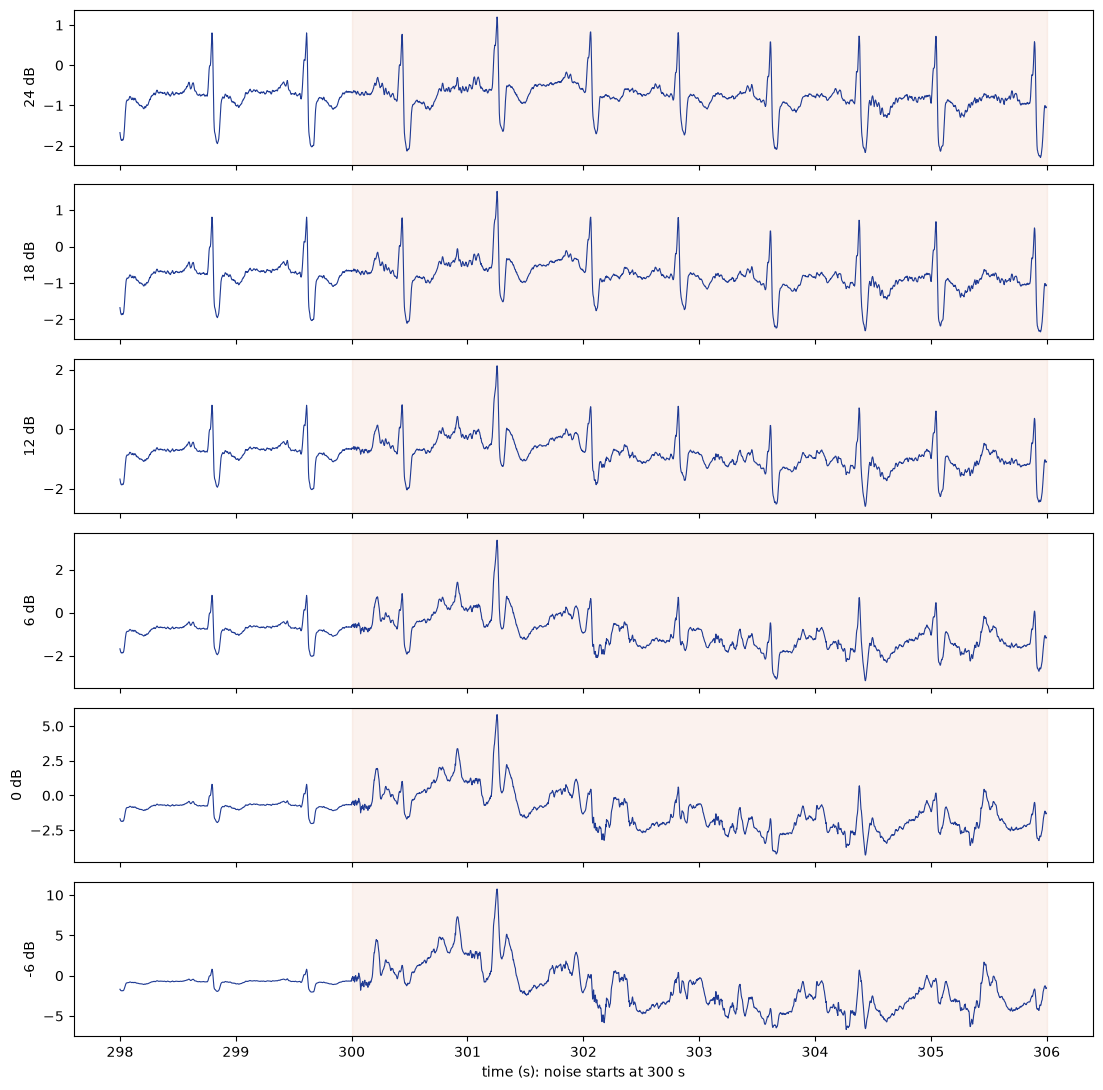

In [11]:
fig, axes = plt.subplots(6, 1, figsize=(11, 11), sharex=True)
for ax, snr in zip(axes, [24, 18, 12, 6, 0, -6]):
    rec = load_record('nstdb', nstdb_name('118', snr))
    t = np.arange(298*360, 306*360)
    ax.plot(t/360, rec.signal[t, 0], lw=.8, color='#1F3A93')
    ax.axvspan(300, 306, color='#D2602A', alpha=.08)
    ax.set_ylabel(f'{snr} dB')
axes[-1].set_xlabel('time (s): noise starts at 300 s')
plt.tight_layout()